#PRE-PROCESSING DATA

In [ ]:
import pandas as pd

# ================== LOAD EXCEL ==================
file_path = "VIXCLS.xlsx"
df = pd.read_excel(file_path)

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# ================== SET INDEX ==================
df = df.set_index("Date")

# ================== MONTHLY MEAN ==================
monthly_mean = df.resample("M").mean()

# ================== FORMAT DATE AS MM-yyyy ==================
monthly_mean.index = monthly_mean.index.strftime("%m-%Y")

# ================== SAVE TO EXCEL ==================
output_file = "monthly_ipi.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    monthly_mean.to_excel(writer, sheet_name="Monthly_Mean")

print("Monthly mean with MM-yyyy dates saved:", output_file)


Monthly mean with MM-yyyy dates saved: monthly_ipi.xlsx


/tmp/ipython-input-178667784.py:14: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_mean = df.resample("M").mean()


In [ ]:
import pandas as pd

# ---------- READ EXCEL WITHOUT CHANGING TYPES ----------
df = pd.read_excel("US_EPU.xlsx", dtype=str)
print(df.dtypes)
print(df.head())

# ---------- CONVERT YEAR & MONTH SAFELY ----------
df["Year"] = df["Year"].astype(int)
df["Month"] = df["Month"].astype(int)

# ---------- CREATE DATE COLUMN ----------
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"].astype(str) + "-01"
)

# MM-YYYY string for display only
df["MM-YYYY"] = df["Date"].dt.strftime("%m-%Y")

# ---------- RESTORE ORIGINAL NUMERIC COLUMNS ----------
for col in df.columns:
    # try converting back to integer where possible
    if col not in ["Date", "MM-YYYY"]:
        try:
            df[col] = pd.to_numeric(df[col], downcast="integer")
        except:
            pass

# ---------- WRITE TO EXCEL ----------
df.to_excel("output.xlsx", index=False)

print("Done. Integer values preserved exactly.")
print(df.dtypes)
print(df.head())


Year     object
Month    object
Value    object
dtype: object
   Year Month               Value
0  2025    12   289.9345646674067
1  2025    11   311.6498466606876
2  2025    10   308.3404087671043
3  2025     9     319.84104140388
4  2025     8  370.92542539915945
Done. Integer values preserved exactly.
Year                int16
Month                int8
Value             float64
Date       datetime64[ns]
MM-YYYY            object
dtype: object
   Year  Month       Value       Date  MM-YYYY
0  2025     12  289.934565 2025-12-01  12-2025
1  2025     11  311.649847 2025-11-01  11-2025
2  2025     10  308.340409 2025-10-01  10-2025
3  2025      9  319.841041 2025-09-01  09-2025
4  2025      8  370.925425 2025-08-01  08-2025


In [ ]:
import pandas as pd

# Read Excel
df = pd.read_excel("output.xlsx")   # file that already has MM-YYYY column

# ---------- TEMPORARY real date for correct sorting ----------
temp_date = pd.to_datetime(df["MM-YYYY"], format="%m-%Y")

# ---------- SORT ----------
df = df.loc[temp_date.sort_values().index]

# ---------- SAVE BACK ----------
df.to_excel("sorted_output.xlsx", index=False)

print("Data sorted in ascending order of MM-YYYY.")


Data sorted in ascending order of MM-YYYY.


In [ ]:
import pandas as pd

# Read Excel WITHOUT modifying any values
df = pd.read_excel("MPU.xlsx")

# Create ONLY the MM-YYYY column as text
df["MM-YYYY"] = (
    df["Month"].astype(int).astype(str).str.zfill(2) + "-" +
    df["Year"].astype(int).astype(str)
)

# Save to new Excel file
df.to_excel("output.xlsx", index=False)

print("MM-YYYY column created. No original values were changed.")


MM-YYYY column created. No original values were changed.


In [ ]:
import pandas as pd

# -------- READ FILE --------
df = pd.read_excel("GPR.xls")

# Assume the mixed date column is named "Date"
# (change the column name if needed)

# -------- PARSE MIXED FORMATS SAFELY --------
# dayfirst=True allows handling of d-m-y
parsed_dates = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# -------- CREATE MM-YYYY COLUMN --------
df["MM-YYYY"] = parsed_dates.dt.strftime("%m-%Y")

# -------- SAVE OUTPUT --------
df.to_excel("output.xlsx", index=False)

print("Mixed date formats converted to MM-YYYY successfully.")


Mixed date formats converted to MM-YYYY successfully.


In [ ]:
import pandas as pd

# -------- READ FILE --------
df = pd.read_excel("Call money rate.xlsx")

# Assume the mixed date column is named "Date"
# (change the column name if needed)

# -------- PARSE MIXED FORMATS SAFELY --------
# dayfirst=True allows handling of d-m-y
parsed_dates = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# -------- CREATE MM-YYYY COLUMN --------
df["MM-YYYY"] = parsed_dates.dt.strftime("%m-%Y")

# -------- SAVE OUTPUT --------
df.to_excel("output.xlsx", index=False)

print("Mixed date formats converted to MM-YYYY successfully.")


Mixed date formats converted to MM-YYYY successfully.


In [ ]:
import pandas as pd

# -------- READ FILE --------
df = pd.read_excel("TPU.xlsx")

# Assume the mixed date column is named "Date"
# (change the column name if needed)

# -------- PARSE MIXED FORMATS SAFELY --------
# dayfirst=True allows handling of d-m-y
parsed_dates = pd.to_datetime(df["DATE"], dayfirst=True, errors="coerce")

# -------- CREATE MM-YYYY COLUMN --------
df["MM-YYYY"] = parsed_dates.dt.strftime("%m-%Y")

# -------- SAVE OUTPUT --------
df.to_excel("output.xlsx", index=False)

print("Mixed date formats converted to MM-YYYY successfully.")


Mixed date formats converted to MM-YYYY successfully.


#OUTPUT GAP

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.filters.hp_filter import hpfilter

# ================== LOAD DATA ==================
# Excel must contain:
# Date column  -> monthly date
# IPI column   -> spliced industrial production index

df = pd.read_excel("IPI_11.xlsx")

# -------- ENSURE DATE IS DATETIME --------
df["Date"] = pd.to_datetime(df["Date"])

# -------- SORT BY DATE (important for HP filter) --------
df = df.sort_values("Date").reset_index(drop=True)

# -------- LOG TRANSFORM OF IPI --------
df["log_IPI"] = np.log(df["Value"])

# ================== HP FILTER ==================
# Monthly data → lambda = 14400
cycle, trend = hpfilter(df["log_IPI"], lamb=14400)

df["Trend_log_IPI"] = trend
df["Output_Gap_percent"] = 100 * cycle   # percentage output gap

# ================== SAVE TO EXCEL ==================
output_file = "output_gap_results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    # Sheet 1 → full dataset with trend & gap
    df.to_excel(writer, sheet_name="HP_Filter_Results", index=False)

    # Sheet 2 → only Date + Output Gap (clean series)
    df[["Date", "Output_Gap_percent"]].to_excel(
        writer, sheet_name="Output_Gap_Only", index=False
    )

print("HP trend and Output Gap calculated and saved to Excel.")


HP trend and Output Gap calculated and saved to Excel.


#VOLATILITY

The below snippets of code calculate the volatility based on daily prices and then convert them to monthly values. There are different types of volatility used, which were further used to calculate GARCH using TPU and GPR. There are a couple of snippets which do data preprocessing but mostly we are calculating daily Volatility.

In [ ]:
#--------------------------------------------volatility from NSE daily data---------------------------------------------
import pandas as pd
import numpy as np


def compute_volatility(input_file, output_file, date_col="Date", price_col="Close"):
    # ---------- READ CSV ----------
    df = pd.read_csv(input_file)

    # ---------- FIX DATE FORMAT (DD-MM-YYYY) ----------
    df[date_col] = pd.to_datetime(df[date_col], dayfirst=True, errors="coerce")

    # ---------- CLEAN PRICE COLUMN ----------
    # Remove commas and convert to numeric
    df[price_col] = (
        df[price_col]
        .astype(str)
        .str.replace(",", "", regex=False)
    )
    df[price_col] = pd.to_numeric(df[price_col], errors="coerce")

    # ---------- DROP INVALID ROWS ----------
    df = df.dropna(subset=[date_col, price_col])

    # ---------- SORT BY DATE ----------
    df = df.sort_values(date_col).reset_index(drop=True)

    # ---------- LOG RETURNS ----------
    df["Log_Return"] = np.log(df[price_col] / df[price_col].shift(1))

    # ---------- ROLLING VOLATILITY ----------
    windows = [7, 21, 63, 252]

    for w in windows:
        df[f"Vol_{w}d"] = df["Log_Return"].rolling(window=w).std()
        df[f"Vol_{w}d_annualized"] = df[f"Vol_{w}d"] * np.sqrt(252)

    # ---------- SAVE OUTPUT ----------
    df.to_csv(output_file, index=False)


# ================== RUN FOR NSE ==================
compute_volatility(
    input_file="NSE_daily_data.csv",
    output_file="nse_volatility.csv",
    date_col="Date",
    price_col="Close"
)

# ================== RUN FOR BSE ==================
compute_volatility(
    input_file="BSE_data_daily.csv",
    output_file="bse_volatility.csv",
    date_col="Date",
    price_col="Close"
)

print("Volatility calculation completed successfully for NSE and BSE.")


FileNotFoundError: [Errno 2] No such file or directory: 'NSE_daily_data.csv'

In [ ]:
#------------------------------------------------------calculated monthly volatility from daily data
import pandas as pd
import numpy as np

# ---------- READ CSV ----------
df = pd.read_csv("NSE_daily_data.csv")

# ---------- CLEAN DATE ----------
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# ---------- CLEAN CLOSE PRICE ----------
df["Close"] = (
    df["Close"]
    .astype(str)                 # ensure string
    .str.replace(",", "", regex=False)  # remove commas
)

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

# ---------- DROP INVALID ROWS ----------
df = df.dropna(subset=["Date", "Close"])

# ---------- SORT BY DATE ----------
df = df.sort_values("Date").reset_index(drop=True)

# ---------- COMPUTE DAILY LOG RETURNS ----------
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# ---------- CREATE MONTH VARIABLE ----------
df["Month"] = df["Date"].dt.to_period("M")

# ---------- REALIZED MONTHLY VOLATILITY ----------
monthly_vol = (
    df.groupby("Month")["Log_Return"]
    .apply(lambda x: np.sqrt(np.sum(x.dropna() ** 2)))
    .reset_index(name="Realized_Volatility")
)

# ---------- CONVERT MONTH TO TIMESTAMP ----------
monthly_vol["Month"] = monthly_vol["Month"].dt.to_timestamp()

# ---------- SAVE ----------
monthly_vol.to_csv("monthly_realized_volatility.csv", index=False)

print("Monthly realized volatility created successfully.")


Monthly realized volatility created successfully.


In [ ]:
#----------------------------------moving average volatility from daily data----------------------------------------------
import pandas as pd
import numpy as np

# ---------- LOAD DATA ----------
df = pd.read_csv("NSE_daily_data.csv")   # change filename if needed

# ---------- CLEAN DATE ----------
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# ---------- CLEAN PRICE COLUMN ----------
df["Close"] = (
    df["Close"]
    .astype(str)                     # ensure string
    .str.replace(",", "", regex=False)   # remove commas
    .str.strip()                     # remove spaces
)

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

# ---------- DROP BAD ROWS ----------
df = df.dropna(subset=["Date", "Close"])

# ---------- SORT ----------
df = df.sort_values("Date").reset_index(drop=True)

# ---------- DAILY LOG RETURNS ----------
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# # =========================================================
# # 1) REALIZED MONTHLY VOLATILITY
# # =========================================================
# df["Month"] = df["Date"].dt.to_period("M")

# monthly_rv = (
#     df.groupby("Month")["Log_Return"]
#     .apply(lambda x: np.sqrt(np.sum(x.dropna() ** 2)))
#     .reset_index(name="Realized_Volatility")
# )

# monthly_rv["Month"] = monthly_rv["Month"].dt.to_timestamp()

# monthly_rv.to_csv("monthly_realized_volatility.csv", index=False)

# =========================================================
# 2) MOVING-AVERAGE VOLATILITY (optional)
# =========================================================
windows = [7, 21, 63, 252]

for w in windows:
    df[f"MA_Vol_{w}"] = df["Log_Return"].rolling(w).std()

df.to_csv("NSE_MA_volatility.csv", index=False)

print("All volatility measures computed successfully.")


All volatility measures computed successfully.


In [ ]:
pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 14.2 MB/s eta 0:00:00


In [ ]:
#---------------------------Garch from daily data----------------------------------------------

import pandas as pd
import numpy as np
from arch import arch_model

# =========================================================
# 1) LOAD AND CLEAN DATA
# =========================================================
df = pd.read_csv("NSE_daily_data.csv")   # change filename if needed

# Clean date
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Clean Close price
df["Close"] = (
    df["Close"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

# Drop bad rows
df = df.dropna(subset=["Date", "Close"])

# Sort
df = df.sort_values("Date").reset_index(drop=True)

# =========================================================
# 2) COMPUTE DAILY LOG RETURNS
# =========================================================
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# Drop first NaN return
returns = 100 * df["Log_Return"].dropna()   # ×100 improves GARCH stability

# =========================================================
# 3) FIT GARCH(1,1) MODEL
# =========================================================
garch = arch_model(returns, vol="GARCH", p=1, q=1)

garch_res = garch.fit(disp="off")

# Conditional volatility (daily)
df.loc[returns.index, "GARCH_Volatility"] = garch_res.conditional_volatility

# =========================================================
# 4) CONVERT DAILY GARCH → MONTHLY GARCH
# =========================================================
df["Month"] = df["Date"].dt.to_period("M")

monthly_garch = (
    df.groupby("Month")["GARCH_Volatility"]
    .mean()                      # average daily conditional volatility
    .reset_index(name="Monthly_GARCH_Vol")
)

monthly_garch["Month"] = monthly_garch["Month"].dt.to_timestamp()

# =========================================================
# 5) SAVE OUTPUT FILES
# =========================================================
df.to_csv("daily_with_garch_volatility_NSE.csv", index=False)
monthly_garch.to_csv("monthly_garch_volatility_NSE.csv", index=False)

print("GARCH volatility estimation completed successfully.")
print("\nGARCH model summary:\n")
print(garch_res.summary())


GARCH volatility estimation completed successfully.

GARCH model summary:

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -11861.7
Distribution:                  Normal   AIC:                           23731.4
Method:            Maximum Likelihood   BIC:                           23759.1
                                        No. Observations:                 7462
Date:                Thu, Feb 12 2026   Df Residuals:                     7461
Time:                        08:54:13   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
----------------------------------------------------------------

In [ ]:
#-------------------------------------------------------monthly to daily tpu
import pandas as pd

# =====================================================
# 1) LOAD MONTHLY TPU FILE
# =====================================================
tpu_monthly = pd.read_excel("TPU.xlsx")   # must contain: Date, TPU

# =====================================================
# 2) CLEAN DATE & TPU COLUMN
# =====================================================
tpu_monthly["Date"] = pd.to_datetime(tpu_monthly["Date"], errors="coerce")
tpu_monthly["TPU"] = pd.to_numeric(tpu_monthly["TPU"], errors="coerce")

# Drop missing rows
tpu_monthly = tpu_monthly.dropna(subset=["Date", "TPU"])

# Sort by date
tpu_monthly = tpu_monthly.sort_values("Date")

# =====================================================
# 3) CONVERT MONTHLY TPU → DAILY (forward fill)
# =====================================================
tpu_daily = (
    tpu_monthly
    .set_index("Date")
    .resample("D")     # create daily frequency
    .ffill()           # keep same TPU within month
    .reset_index()
)

# =====================================================
# 4) SAVE DAILY TPU
# =====================================================
tpu_daily.to_excel("daily_tpu.xlsx", index=False)

print("Daily TPU series created and saved as 'daily_tpu.xlsx'.")


/tmp/ipython-input-2497142521.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  tpu_monthly["Date"] = pd.to_datetime(tpu_monthly["Date"], errors="coerce")


Daily TPU series created and saved as 'daily_tpu.xlsx'.


In [ ]:
#---------------------------------------------------------aligning dates from two sheets
import pandas as pd

# =====================================================
# 1) LOAD FILES
# =====================================================
prices = pd.read_csv("NSE_daily_data.csv")        # CSV → Date, Close
uncert = pd.read_excel("Garch.xlsx")       # Excel → Date, TPU, GPR

# =====================================================
# 2) CLEAN DATE COLUMNS
# =====================================================
prices["Date"] = pd.to_datetime(prices["Date"], errors="coerce")
uncert["Date"] = pd.to_datetime(uncert["Date"], errors="coerce")

# =====================================================
# 3) CLEAN NUMERIC VALUES
# =====================================================
# --- Close price ---
prices["Close"] = (
    prices["Close"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
)
prices["Close"] = pd.to_numeric(prices["Close"], errors="coerce")

# --- TPU & GPR ---
uncert["TPU"] = pd.to_numeric(uncert["TPU"], errors="coerce")
uncert["GPR"] = pd.to_numeric(uncert["GPR"], errors="coerce")

# =====================================================
# 4) ALIGN TO NSE TRADING DAYS (MASTER INDEX)
# =====================================================
df = prices.merge(uncert, on="Date", how="left")

# =====================================================
# 5) FORWARD-FILL UNCERTAINTY VARIABLES
# =====================================================
df["TPU"] = df["TPU"].ffill()
df["GPR"] = df["GPR"].ffill()

# =====================================================
# 6) DROP ROWS WITHOUT PRICE
# =====================================================
df = df.dropna(subset=["Close"])

# Sort by date
df = df.sort_values("Date").reset_index(drop=True)

# =====================================================
# 7) SAVE ALIGNED DATASET
# =====================================================
df.to_excel("aligned_daily_dataset.xlsx", index=False)

print("Aligned dataset ready for GARCH-X saved as 'aligned_daily_dataset.xlsx'.")


/tmp/ipython-input-1053737167.py:12: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  prices["Date"] = pd.to_datetime(prices["Date"], errors="coerce")


Aligned dataset ready for GARCH-X saved as 'aligned_daily_dataset.xlsx'.


In [ ]:
#------------------------------------------------final garch
import pandas as pd
import numpy as np
from arch import arch_model

# =====================================================
# 1) LOAD MONTHLY DATA
# =====================================================
df = pd.read_excel("GPR_TPU.xlsx")
# Must contain: Date, NSE_Close, TPU, GPR

# =====================================================
# 2) CLEAN VARIABLES
# =====================================================
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["NSE"] = pd.to_numeric(df["NSE"], errors="coerce")
df["TPU"] = pd.to_numeric(df["TPU"], errors="coerce")
df["GPR"] = pd.to_numeric(df["GPR"], errors="coerce")

df = df.dropna(subset=["NSE", "TPU", "GPR"])
df = df.sort_values("Date").reset_index(drop=True)

# =====================================================
# 3) COMPUTE MONTHLY LOG RETURNS
# =====================================================
df["Return"] = np.log(df["NSE"] / df["NSE"].shift(1))

# Drop first NaN return and scale ×100 for GARCH stability
returns = 100 * df["Return"].dropna()

# Align TPU & GPR with returns
exog = df.loc[returns.index, ["TPU", "GPR"]]

# =====================================================
# 4) ESTIMATE MONTHLY GARCH-X
# =====================================================
model = arch_model(
    returns,
    mean="Constant",
    vol="GARCH",      # change to "EGARCH" for EGARCH-X
    p=1,
    q=1,
    x=exog
)

res = model.fit(disp="off")

# =====================================================
# 5) SAVE CONDITIONAL VOLATILITY
# =====================================================
df.loc[returns.index, "Monthly_GARCHX_Vol"] = res.conditional_volatility

# =====================================================
# 6) SAVE OUTPUT
# =====================================================
df.to_excel("monthly_garchx_results.xlsx", index=False)

print("Monthly GARCH-X estimation completed.\n")
print(res.summary())


Monthly GARCH-X estimation completed.

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1024.09
Distribution:                  Normal   AIC:                           2056.18
Method:            Maximum Likelihood   BIC:                           2071.25
                                        No. Observations:                  320
Date:                Mon, Feb 16 2026   Df Residuals:                      319
Time:                        12:59:04   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.9819      0.29

GARCH

In [ ]:
import pandas as pd
import numpy as np
from arch import arch_model

# =====================================================
# 1) LOAD ALIGNED DAILY DATA
# =====================================================
df = pd.read_excel("aligned_daily_dataset.xlsx")

# Ensure proper types
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df["TPU"] = pd.to_numeric(df["TPU"], errors="coerce")
df["GPR"] = pd.to_numeric(df["GPR"], errors="coerce")

# Drop missing rows
df = df.dropna(subset=["Date", "Close", "TPU", "GPR"])

# Sort
df = df.sort_values("Date").reset_index(drop=True)

# =====================================================
# 2) DAILY LOG RETURNS
# =====================================================
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# Scale returns by 100 (standard for GARCH stability)
returns = 100 * df["Log_Return"].dropna()

# Align TPU & GPR with returns index
exog = df.loc[returns.index, ["TPU", "GPR"]]

# =====================================================
# 3) GARCH-X MODEL  (change vol="EGARCH" if needed)
# =====================================================
model = arch_model(
    returns,
    mean="Constant",
    vol="GARCH",     # ← change to "EGARCH" for EGARCH-X
    p=1,
    q=1,
    x=exog
)

res = model.fit(disp="off")

# Store daily conditional volatility
df.loc[returns.index, "GARCHX_Volatility"] = res.conditional_volatility

# =====================================================
# 4) CONVERT DAILY → MONTHLY VOLATILITY
# =====================================================
df["Month"] = df["Date"].dt.to_period("M")

monthly_vol = (
    df.groupby("Month")["GARCHX_Volatility"]
    .mean()                     # monthly average conditional volatility
    .reset_index(name="Monthly_GARCHX_Vol")
)

monthly_vol["Month"] = monthly_vol["Month"].dt.to_timestamp()

# =====================================================
# 5) SAVE OUTPUT FILES
# =====================================================
df.to_excel("daily_garchx_results.xlsx", index=False)
monthly_vol.to_excel("monthly_garchx_volatility.xlsx", index=False)

print("GARCH-X estimation completed successfully.\n")
print(res.summary())


GARCH-X estimation completed successfully.

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -11845.8
Distribution:                  Normal   AIC:                           23699.7
Method:            Maximum Likelihood   BIC:                           23727.3
                                        No. Observations:                 7441
Date:                Thu, Feb 12 2026   Df Residuals:                     7440
Time:                        10:02:02   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.078

#Volatility with monthly data

In [ ]:
# =====================================================
# 0) IMPORT LIBRARIES
# =====================================================
import pandas as pd
import numpy as np
from scipy.optimize import minimize

# =====================================================
# 1) LOAD AND CLEAN DATA
# =====================================================
df = pd.read_excel("GPR_TPU.xlsx")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["NSE"] = pd.to_numeric(df["NSE"], errors="coerce")
df["TPU"] = pd.to_numeric(df["TPU"], errors="coerce")
df["GPR"] = pd.to_numeric(df["GPR"], errors="coerce")

df = df.dropna().sort_values("Date").reset_index(drop=True)

# =====================================================
# 2) COMPUTE MONTHLY LOG RETURNS
# =====================================================
df["Return"] = np.log(df["NSE"] / df["NSE"].shift(1))
df = df.dropna().reset_index(drop=True)

# Scale returns (important for GARCH stability)
r = 100 * df["Return"].values
TPU = df["TPU"].values
GPR = df["GPR"].values
T = len(r)

# =====================================================
# 3) DEFINE GARCH-X LOG-LIKELIHOOD
# =====================================================
def garchx_loglik(params, r, TPU, GPR):
    omega, alpha, beta, d1, d2 = params

    T = len(r)
    sigma2 = np.zeros(T)

    # Initialize variance
    sigma2[0] = np.var(r)

    for t in range(1, T):
        sigma2[t] = (
            omega
            + alpha * r[t-1]**2
            + beta * sigma2[t-1]
            + d1 * TPU[t]
            + d2 * GPR[t]
        )

        # Penalize invalid variance
        if sigma2[t] <= 0:
            return 1e10

    # Log-likelihood (Gaussian)
    ll = -0.5 * np.sum(
        np.log(2 * np.pi)
        + np.log(sigma2)
        + (r**2) / sigma2
    )

    return -ll  # minimize negative log-likelihood

# =====================================================
# 4) PARAMETER ESTIMATION
# =====================================================
init_params = [0.1, 0.05, 0.9, 0.01, 0.01]

bounds = [
    (1e-6, None),   # omega > 0
    (0, 1),         # alpha
    (0, 1),         # beta
    (None, None),   # d1
    (None, None)    # d2
]

result = minimize(
    garchx_loglik,
    init_params,
    args=(r, TPU, GPR),
    bounds=bounds
)

omega, alpha, beta, d1, d2 = result.x

# =====================================================
# 5) COMPUTE CONDITIONAL VARIANCE & VOLATILITY
# =====================================================
sigma2 = np.zeros(T)
sigma2[0] = np.var(r)

for t in range(1, T):
    sigma2[t] = (
        omega
        + alpha * r[t-1]**2
        + beta * sigma2[t-1]
        + d1 * TPU[t]
        + d2 * GPR[t]
    )

df["GARCHX_Variance"] = sigma2
df["GARCHX_Volatility"] = np.sqrt(sigma2)

# =====================================================
# 6) SAVE RESULTS
# =====================================================
df.to_excel("monthly_garchx_results.xlsx", index=False)

# =====================================================
# 7) PRINT OUTPUT
# =====================================================
print("\n===== GARCH-X ESTIMATION RESULTS =====")
print(f"omega  = {omega:.6f}")
print(f"alpha  = {alpha:.6f}")
print(f"beta   = {beta:.6f}")
print(f"d1(TPU)= {d1:.6f}")
print(f"d2(GPR)= {d2:.6f}")

print("\n===== MODEL DIAGNOSTICS =====")
print(f"alpha + beta = {alpha + beta:.4f}")

if alpha + beta < 1:
    print("✔ Stationary volatility process")
else:
    print("⚠ Non-stationary (alpha + beta >= 1)")

# Long-run variance
long_run_var = omega / (1 - alpha - beta) if (alpha + beta) < 1 else np.nan
print(f"Long-run variance = {long_run_var:.6f}")

print("\nResults saved to: monthly_garchx_results.xlsx")


===== GARCH-X ESTIMATION RESULTS =====
omega  = 4.067923
alpha  = 0.109654
beta   = 0.823041
d1(TPU)= -0.005012
d2(GPR)= -0.009680

===== MODEL DIAGNOSTICS =====
alpha + beta = 0.9327
✔ Stationary volatility process
Long-run variance = 60.440534

Results saved to: monthly_garchx_results.xlsx


#PLOTTING

Individual variable plots saved in 'variable_plots' folder.


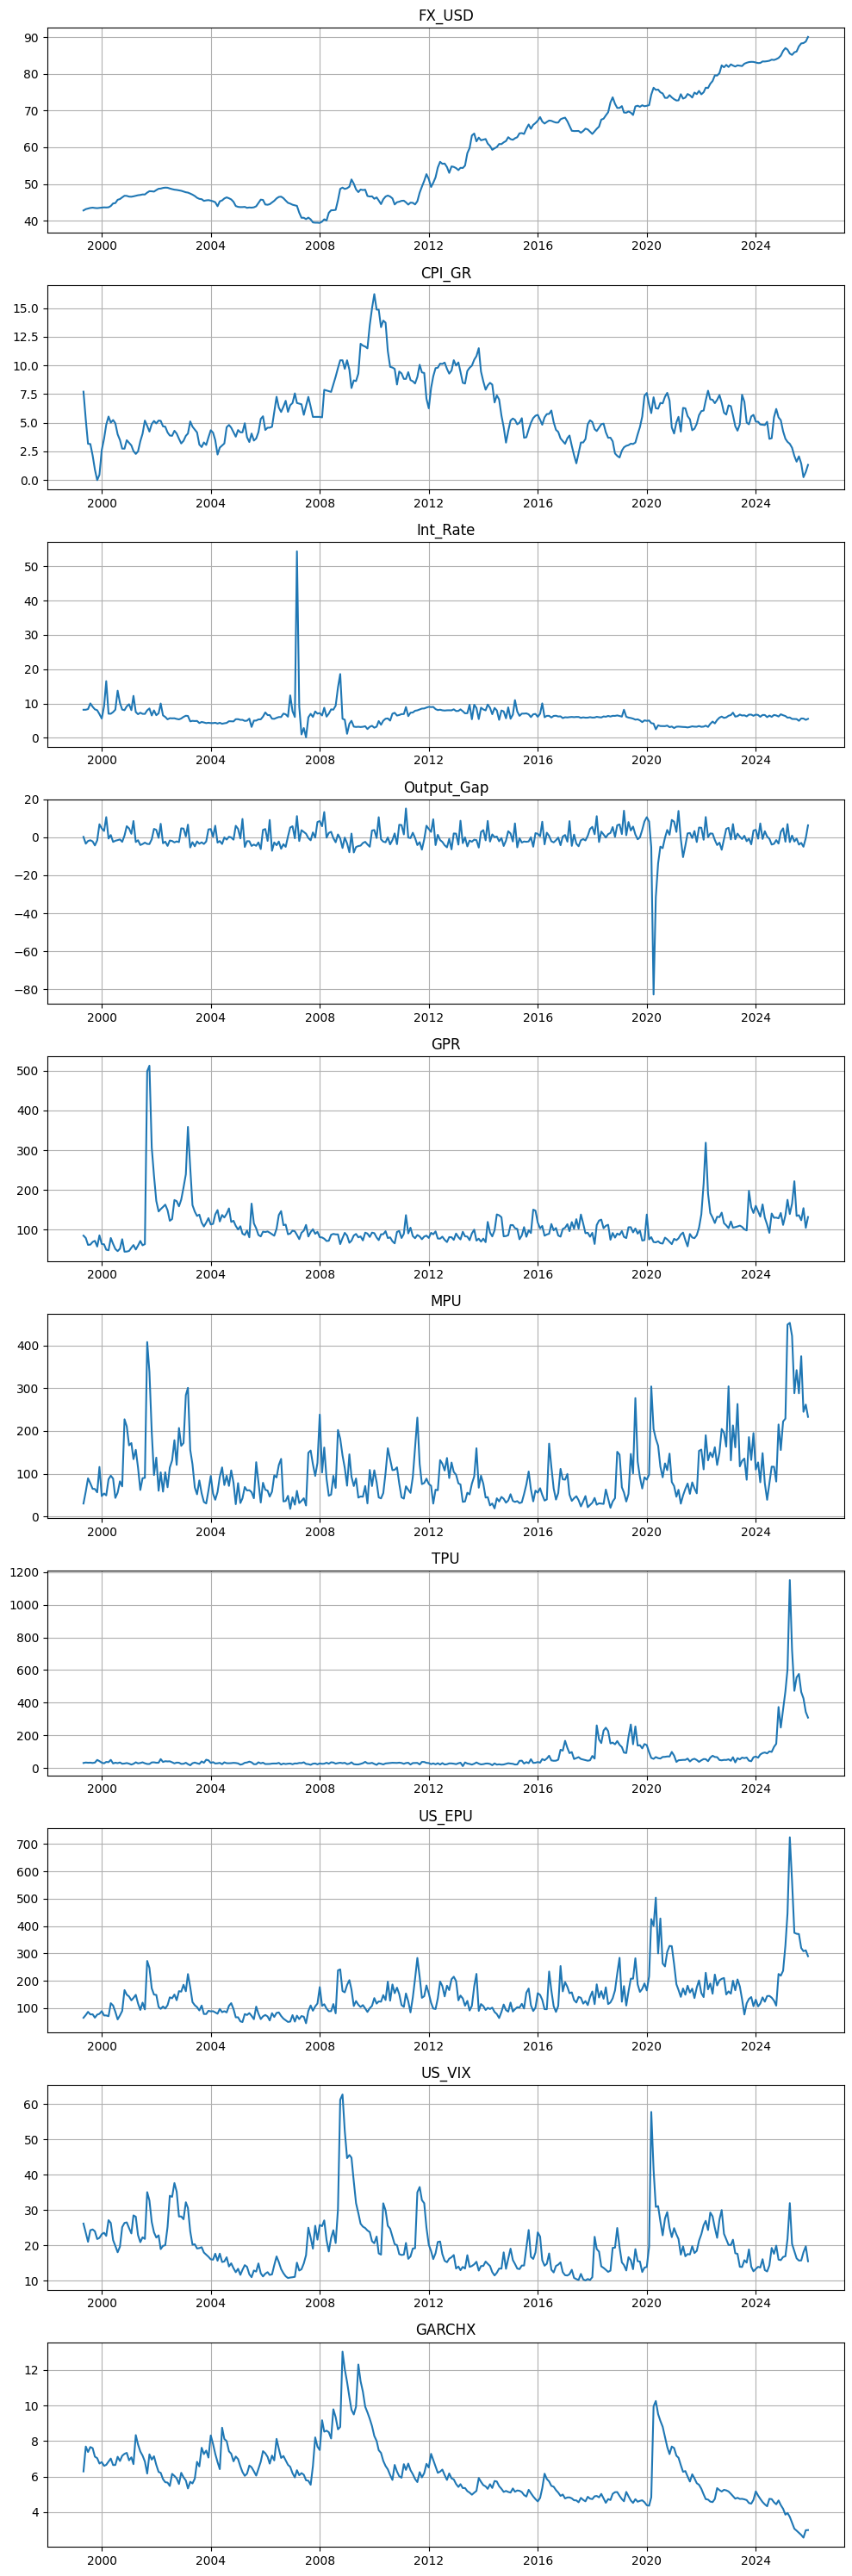

Combined multi-panel plot saved as 'all_variables_timeseries.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---------- LOAD DATA ----------
df = pd.read_excel("Compiled.xlsx")
# or: df = pd.read_csv("merged_monthly_data.csv")

# ---------- ENSURE DATE COLUMN ----------
# Change column name if your date column is different
date_col = "Date"
df[date_col] = pd.to_datetime(df[date_col])

# ---------- SET DATE AS INDEX ----------
df = df.sort_values(date_col).set_index(date_col)

# ---------- SELECT NUMERIC COLUMNS ----------
numeric_cols = df.select_dtypes(include="number").columns

# ---------- CREATE FOLDER FOR INDIVIDUAL PLOTS ----------
os.makedirs("variable_plots", exist_ok=True)

# =========================================================
# 1) INDIVIDUAL TIME-SERIES PLOTS
# =========================================================
for col in numeric_cols:
    plt.figure()
    plt.plot(df.index, df[col])
    plt.title(f"{col} Over Time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(True)

    plt.tight_layout()
    plt.savefig(f"variable_plots/{col}.png", dpi=300)
    plt.close()

print("Individual variable plots saved in 'variable_plots' folder.")

# =========================================================
# 2) COMBINED MULTI-PANEL FIGURE
# =========================================================
n = len(numeric_cols)

plt.figure(figsize=(10, 3 * n))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n, 1, i)
    plt.plot(df.index, df[col])
    plt.title(col)
    plt.grid(True)

plt.tight_layout()
plt.savefig("all_variables_timeseries.png", dpi=300)
plt.show()

print("Combined multi-panel plot saved as 'all_variables_timeseries.png'.")


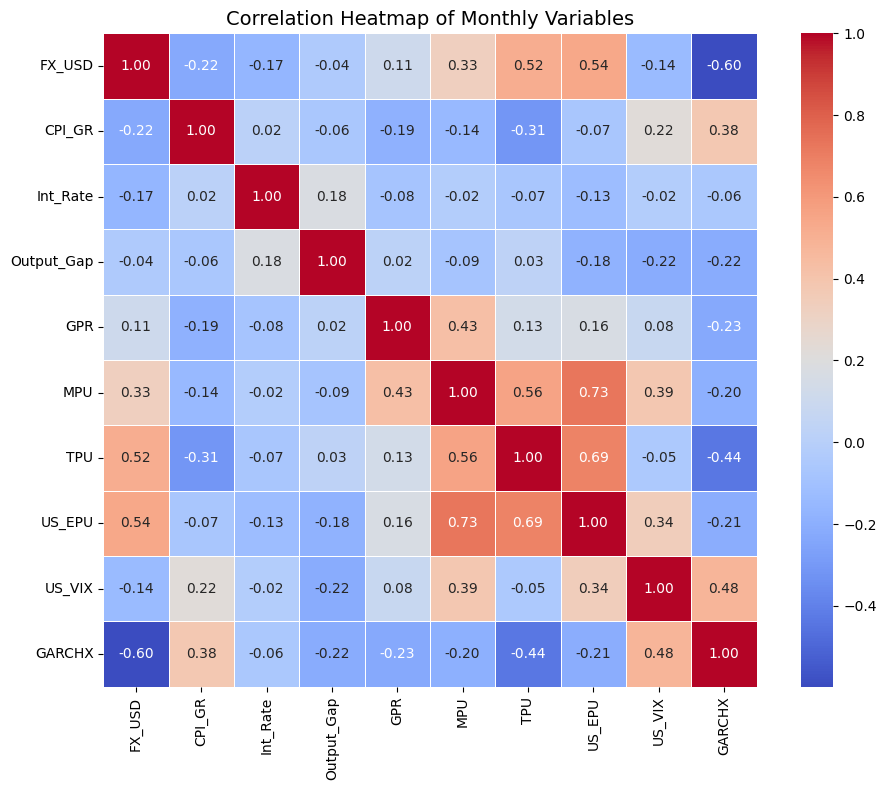

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- READ MERGED MONTHLY DATA ----------
df = pd.read_excel("Compiled.xlsx")
# or use: pd.read_csv("merged_monthly_data.csv")

# ---------- OPTIONAL: DROP DATE COLUMN ----------
# Keep only numeric variables for correlation
numeric_df = df.select_dtypes(include="number")

# ---------- COMPUTE CORRELATION MATRIX ----------
corr_matrix = numeric_df.corr()

# ---------- PLOT HEATMAP ----------
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,        # show correlation values
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Monthly Variables", fontsize=14)
plt.tight_layout()

# ---------- SAVE FIGURE ----------
plt.savefig("correlation_heatmap.png", dpi=300)

# ---------- SHOW ----------
plt.show()


#STATIONARITY

In [ ]:
# import pandas as pd
# from statsmodels.tsa.stattools import adfuller

# # ---------- LOAD YOUR MERGED MONTHLY DATA ----------
# # Change file name if needed
# df = pd.read_excel("Compiled.xlsx")
# # or: df = pd.read_csv("merged_monthly_data.csv")

# # ---------- KEEP ONLY NUMERIC COLUMNS ----------
# numeric_df = df.select_dtypes(include="number")

# # ---------- FUNCTION TO RUN ADF ----------
# def adf_test(series):
#     series = series.dropna()

#     result = adfuller(series, autolag="AIC")

#     return pd.Series({
#         "ADF Statistic": result[0],
#         "p-value": result[1],
#         "Lags Used": result[2],
#         "Observations": result[3],
#         "Critical Value 1%": result[4]["1%"],
#         "Critical Value 5%": result[4]["5%"],
#         "Critical Value 10%": result[4]["10%"],
#         "Stationary? (5%)": "Yes" if result[1] < 0.05 else "No"
#     })

# # ---------- APPLY TO ALL COLUMNS ----------
# adf_results = numeric_df.apply(adf_test).T

# # ---------- DISPLAY RESULTS ----------
# print("\nADF Unit Root Test Results:\n")
# print(adf_results)

# # ---------- SAVE RESULTS ----------
# adf_results.to_excel("ADF_results.xlsx")
# adf_results.to_csv("ADF_results.csv")

# print("\nADF results saved to 'ADF_results.xlsx' and 'ADF_results.csv'")



ADF Unit Root Test Results:

           ADF Statistic   p-value Lags Used Observations Critical Value 1%  \
FX_USD          0.997843  0.994243        17          342         -3.449616   
CPI_GR         -1.903368  0.330479        14          345         -3.449447   
Int_Rate       -2.572892   0.09873        17          342         -3.449616   
Output_Gap     -5.999355       0.0        17          342         -3.449616   
GPR            -6.009099       0.0         2          357         -3.448801   
MPU            -4.597185  0.000131         3          356         -3.448853   
TPU             0.458915  0.983569        10          349         -3.449227   
US_EPU         -3.700322  0.004109         3          356         -3.448853   
US_VIX         -4.907484  0.000034         2          357         -3.448801   
BSE_VOL          -3.6266  0.005272         5          354         -3.448958   
NSE_VOL        -3.369231  0.012054         6          353         -3.449011   

           Critical V

In [ ]:
# import pandas as pd
# from statsmodels.tsa.stattools import adfuller

# # ---------- LOAD MERGED MONTHLY DATA ----------
# df = pd.read_excel("Compiled.xlsx")
# # or: df = pd.read_csv("merged_monthly_data.csv")

# # ---------- IDENTIFY NUMERIC COLUMNS ----------
# numeric_cols = df.select_dtypes(include="number").columns

# # ---------- STORE RESULTS ----------
# adf_summary = []
# transformed_df = df.copy()

# # ---------- FUNCTION: ADF TEST ----------
# def is_stationary(series, alpha=0.05):
#     series = series.dropna()
#     if len(series) < 10:
#         return True, None  # too small → treat as stationary

#     result = adfuller(series, autolag="AIC")
#     p_value = result[1]

#     return p_value < alpha, p_value


# # ---------- LOOP THROUGH COLUMNS ----------
# for col in numeric_cols:

#     stationary, p_val = is_stationary(transformed_df[col])

#     # If NOT stationary → difference once
#     if not stationary:
#         transformed_df[col] = transformed_df[col].diff()
#         stationary_after, p_val_after = is_stationary(transformed_df[col])
#     else:
#         stationary_after, p_val_after = stationary, p_val

#     # Save summary info
#     adf_summary.append({
#         "Variable": col,
#         "Original p-value": p_val,
#         "Differenced?": "Yes" if not stationary else "No",
#         "Final p-value": p_val_after,
#         "Final Stationary?": "Yes" if stationary_after else "No"
#     })


# # ---------- CREATE SUMMARY TABLE ----------
# adf_summary_df = pd.DataFrame(adf_summary)

# # ---------- SAVE TO NEW EXCEL WITH TWO SHEETS ----------
# output_file = "stationarity_transformed_data.xlsx"

# with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

#     # Sheet 1 → transformed dataset (ready for regression)
#     transformed_df.to_excel(writer, sheet_name="Transformed_Data", index=False)

#     # Sheet 2 → ADF summary table
#     adf_summary_df.to_excel(writer, sheet_name="ADF_Summary", index=False)

# print("Stationarity testing, differencing, and export completed.")


Stationarity testing, differencing, and export completed.


In [ ]:
pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 10.3 MB/s eta 0:00:00


In [ ]:
# =====================================================
# 0) IMPORT LIBRARIES
# =====================================================
import pandas as pd
from statsmodels.tsa.stattools import adfuller
from arch.unitroot import PhillipsPerron

# =====================================================
# 1) LOAD DATA
# =====================================================
df = pd.read_excel("Compiled.xlsx")

# Keep only numeric columns
numeric_cols = df.select_dtypes(include="number").columns

# =====================================================
# 2) FUNCTION: ADF TEST
# =====================================================

def adf_full_test(series):
    series = series.dropna()

    results = {}

    # ADF with constant
    res_c = adfuller(series, regression="c", autolag="AIC")
    results["ADF (const) p-value"] = res_c[1]

    # ADF with trend
    res_ct = adfuller(series, regression="ct", autolag="AIC")
    results["ADF (trend) p-value"] = res_ct[1]

    return results
# =====================================================
# 3) FUNCTION: PP TEST
# =====================================================
def pp_test(series):
    series = series.dropna()

    if len(series) < 10:
        return None

    pp = PhillipsPerron(series)

    return {
        "PP Statistic": pp.stat,
        "PP p-value": pp.pvalue
    }

# =====================================================
# 4) APPLY TESTS TO ALL VARIABLES
# =====================================================
results = []

for col in numeric_cols:

    series = df[col].dropna()

    adf_res = adf_test(series)
    pp_res = pp_test(series)

    if adf_res is None or pp_res is None:
        continue

    # Decision rule
    adf_stationary = adf_res["ADF p-value"] < 0.05
    pp_stationary = pp_res["PP p-value"] < 0.05

    if adf_stationary and pp_stationary:
        conclusion = "Stationary ✅"
    elif not adf_stationary and not pp_stationary:
        conclusion = "Non-Stationary ❌"
    else:
        conclusion = "Mixed ⚠️"

    results.append({
        "Variable": col,
        "ADF p-value": adf_res["ADF p-value"],
        "PP p-value": pp_res["PP p-value"],
        "ADF Stationary": "Yes" if adf_stationary else "No",
        "PP Stationary": "Yes" if pp_stationary else "No",
        "Final Conclusion": conclusion
    })

# =====================================================
# 5) CREATE RESULTS TABLE
# =====================================================
results_df = pd.DataFrame(results)

print("\n===== STATIONARITY TEST RESULTS (ADF + PP) =====\n")
print(results_df)

# =====================================================
# 6) SAVE OUTPUT
# =====================================================
results_df.to_excel("ADF_PP_results.xlsx", index=False)

print("\nResults saved to 'ADF_PP_results.xlsx'")


===== STATIONARITY TEST RESULTS (ADF + PP) =====

     Variable   ADF p-value    PP p-value ADF Stationary PP Stationary  \
0      FX_USD  9.894803e-01  9.939008e-01             No            No   
1      CPI_GR  7.039985e-01  1.600105e-01             No            No   
2    Int_Rate  2.339351e-06  1.524792e-28            Yes           Yes   
3  Output_Gap  1.719106e-06  4.068711e-22            Yes           Yes   
4         GPR  1.455755e-07  4.164267e-10            Yes           Yes   
5         MPU  6.073756e-04  4.685129e-12            Yes           Yes   
6         TPU  9.814322e-01  1.487425e-03             No           Yes   
7      US_EPU  5.432268e-03  4.958215e-07            Yes           Yes   
8      US_VIX  1.307216e-04  4.332746e-06            Yes           Yes   
9      GARCHX  4.129432e-02  4.596649e-02            Yes           Yes   

   Final Conclusion  
0  Non-Stationary ❌  
1  Non-Stationary ❌  
2      Stationary ✅  
3      Stationary ✅  
4      Stationary ✅  
5 

In [ ]:
# =====================================================
# 0) IMPORT LIBRARIES
# =====================================================
import pandas as pd
import numpy as np

# =====================================================
# 1) LOAD DATA
# =====================================================
df = pd.read_excel("Compiled.xlsx")

# Load stationarity results (from previous step)
results_df = pd.read_excel("ADF_PP_results.xlsx")

# Copy dataset for transformation
transformed_df = df.copy()

# =====================================================
# 2) DEFINE TRANSFORMATION FUNCTION
# =====================================================
def transform_series(series, method):

    if method == "log":
        return np.log(series.replace(0, np.nan))

    elif method == "diff":
        return series.diff()

    elif method == "log_diff":
        return np.log(series.replace(0, np.nan)).diff()

    else:
        return series

# =====================================================
# 3) APPLY TRANSFORMATIONS BASED ON TEST RESULTS
# =====================================================
transformation_summary = []

for _, row in results_df.iterrows():

    col = row["Variable"]
    status = row["Final Conclusion"]

    if col not in transformed_df.columns:
        continue

    # -------------------------------
    # CASE 1: STATIONARY
    # -------------------------------
    if "Stationary" in status:
        method = "None"
        transformed_df[col] = transformed_df[col]

    # -------------------------------
    # CASE 2: NON-STATIONARY
    # -------------------------------
    elif "Non-Stationary" in status:

        # Step 1: Try log transform
        transformed_df[col] = transform_series(transformed_df[col], "log")

        # Step 2: Difference after log
        transformed_df[col] = transform_series(transformed_df[col], "diff")

        method = "log + diff"

    # -------------------------------
    # CASE 3: MIXED
    # -------------------------------
    else:

        # Conservative approach
        transformed_df[col] = transform_series(transformed_df[col], "log")

        method = "log only"

    transformation_summary.append({
        "Variable": col,
        "Original Status": status,
        "Transformation Applied": method
    })

# =====================================================
# 4) CLEAN FINAL DATA
# =====================================================
transformed_df = transformed_df.dropna().reset_index(drop=True)

# =====================================================
# 5) SAVE OUTPUT
# =====================================================
summary_df = pd.DataFrame(transformation_summary)

with pd.ExcelWriter("final_transformed_dataset.xlsx") as writer:
    transformed_df.to_excel(writer, sheet_name="Transformed_Data", index=False)
    summary_df.to_excel(writer, sheet_name="Transformation_Summary", index=False)

print("\nTransformation completed successfully.")
print("Saved as: final_transformed_dataset.xlsx")


Transformation completed successfully.
Saved as: final_transformed_dataset.xlsx


Individual variable plots saved in 'variable_plots' folder.


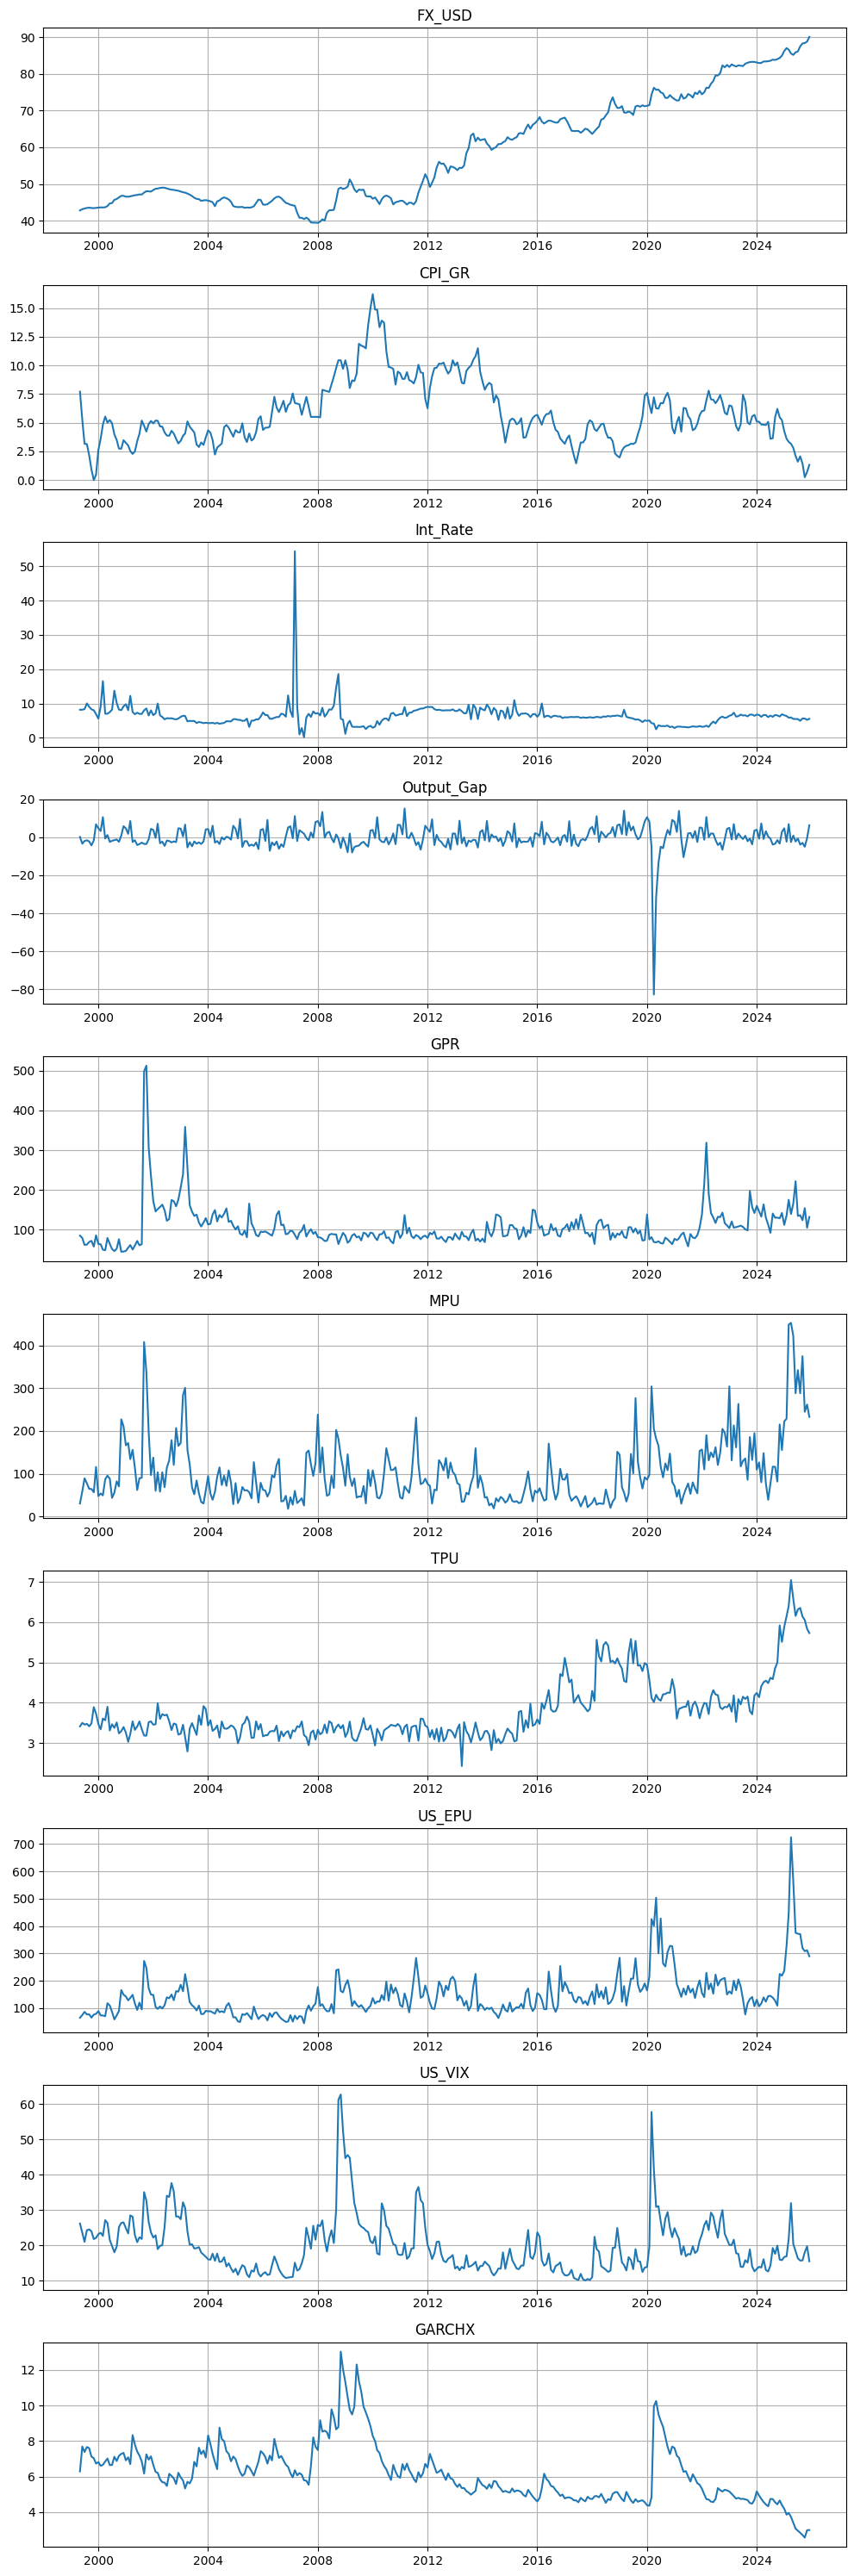

Combined multi-panel plot saved as 'all_variables_timeseries.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---------- LOAD DATA ----------
df = pd.read_excel("final_transformed_dataset.xlsx")
# or: df = pd.read_csv("merged_monthly_data.csv")

# ---------- ENSURE DATE COLUMN ----------
# Change column name if your date column is different
date_col = "Date"
df[date_col] = pd.to_datetime(df[date_col])

# ---------- SET DATE AS INDEX ----------
df = df.sort_values(date_col).set_index(date_col)

# ---------- SELECT NUMERIC COLUMNS ----------
numeric_cols = df.select_dtypes(include="number").columns

# ---------- CREATE FOLDER FOR INDIVIDUAL PLOTS ----------
os.makedirs("variable_plots", exist_ok=True)

# =========================================================
# 1) INDIVIDUAL TIME-SERIES PLOTS
# =========================================================
for col in numeric_cols:
    plt.figure()
    plt.plot(df.index, df[col])
    plt.title(f"{col} Over Time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(True)

    plt.tight_layout()
    plt.savefig(f"variable_plots/{col}.png", dpi=300)
    plt.close()

print("Individual variable plots saved in 'variable_plots' folder.")

# =========================================================
# 2) COMBINED MULTI-PANEL FIGURE
# =========================================================
n = len(numeric_cols)

plt.figure(figsize=(10, 3 * n))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n, 1, i)
    plt.plot(df.index, df[col])
    plt.title(col)
    plt.grid(True)

plt.tight_layout()
plt.savefig("all_variables_timeseries.png", dpi=300)
plt.show()

print("Combined multi-panel plot saved as 'all_variables_timeseries.png'.")


#Co-Integration

In [ ]:
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# =====================================================
# LOAD ORIGINAL (LEVEL) DATA
# =====================================================
df = pd.read_excel("Compiled.xlsx")   # <-- IMPORTANT

# =====================================================
# SELECT VARIABLES (LEVELS ONLY)
# =====================================================
cols = [
    "TPU",
    "GPR",
    "CPI_GR",
    "MPU",
    "US_EPU",
    "Int_Rate",
    "FX_USD",
    "Output_Gap",
    "US_VIX"
]

# Check column names
print(df.columns)

# Extract data
data = df[cols].dropna()

# =====================================================
# JOHANSEN TEST
# =====================================================
johansen_test = coint_johansen(data, det_order=0, k_ar_diff=1)

# =====================================================
# OUTPUT
# =====================================================
print("Trace Statistics:")
print(johansen_test.lr1)

print("\nCritical Values (5%):")
print(johansen_test.cvt[:, 1])

Index(['Date', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU',
       'TPU', 'US_EPU', 'US_VIX', 'GARCHX'],
      dtype='object')
Trace Statistics:
[407.30479461 297.10044682 207.66069761 144.10489573  92.72009644
  61.14252395  31.36610171  10.30414734   0.48842786]

Critical Values (5%):
[197.3772 159.529  125.6185  95.7542  69.8189  47.8545  29.7961  15.4943
   3.8415]


In [ ]:
from statsmodels.tsa.vector_ar.vecm import VECM

model = VECM(
    data,
    k_ar_diff=1,
    coint_rank=6
)

vecm_res = model.fit()

print(vecm_res.summary())

Det. terms outside the coint. relation & lagged endog. parameters for equation TPU
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
L1.TPU           -0.1073      0.067     -1.596      0.110      -0.239       0.024
L1.GPR           -0.0168      0.085     -0.197      0.844      -0.184       0.150
L1.CPI_GR        -1.0016      3.498     -0.286      0.775      -7.857       5.854
L1.MPU            0.0726      0.075      0.967      0.334      -0.075       0.220
L1.US_EPU        -0.0656      0.087     -0.750      0.453      -0.237       0.106
L1.Int_Rate      -0.1953      0.838     -0.233      0.816      -1.838       1.447
L1.FX_USD         2.0187      3.460      0.583      0.560      -4.763       8.801
L1.Output_Gap     0.5362      0.470      1.141      0.254      -0.385       1.457
L1.US_VIX         0.9974      0.755      1.321      0.186      -0.482       2.477
Det. terms outs

#REGRESSION

In [ ]:
import pandas as pd
import statsmodels.api as sm

# =========================================================
# 1) LOAD MERGED MONTHLY DATASET
# =========================================================
df = pd.read_excel("final_transformed_dataset.xlsx")
# or: df = pd.read_csv("merged_monthly_data.csv")

# =========================================================
# 2) CREATE INTERACTION TERM  TPU × GPR
# =========================================================
df["TPU_GPR"] = df["TPU"] * df["GPR"]

# =========================================================
# 3) DEFINE DEPENDENT AND INDEPENDENT VARIABLES
# =========================================================
y = df["NSE_VOL"]   # <-- change column name if needed

X = df[
    [
        "TPU",
        "GPR",
        "TPU_GPR",
        "CPI_GR",
        "MPU",
        "US_EPU",
        "Int_Rate",
        "FX_USD",
        "Output_Gap",
        "US_VIX"
    ]
]

# Add constant (α)
X = sm.add_constant(X)

# Drop missing observations
data = pd.concat([y, X], axis=1).dropna()
y = data["NSE_VOL"]
X = data.drop(columns=["NSE_VOL"])

# =========================================================
# 4) RUN OLS WITH HAC (Newey-West) STANDARD ERRORS
# =========================================================
model = sm.OLS(y, X)

results = model.fit(cov_type="HAC", cov_kwds={"maxlags": 12})
# 12 lags ≈ 1 year for monthly data

# =========================================================
# 5) PRINT RESULTS
# =========================================================
print(results.summary())

# =========================================================
# 6) SAVE REGRESSION TABLE TO FILE
# =========================================================
with open("regression_results.txt", "w") as f:
    f.write(results.summary().as_text())

print("\nRegression completed. Results saved to 'regression_results.txt'.")


                            OLS Regression Results                            
Dep. Variable:                NSE_VOL   R-squared:                       0.413
Model:                            OLS   Adj. R-squared:                  0.396
Method:                 Least Squares   F-statistic:                     13.27
Date:                Thu, 12 Feb 2026   Prob (F-statistic):           9.56e-20
Time:                        09:34:43   Log-Likelihood:                 824.52
No. Observations:                 359   AIC:                            -1627.
Df Residuals:                     348   BIC:                            -1584.
Df Model:                          10                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0283      0.009      3.080      0.0

In [ ]:
import pandas as pd
import statsmodels.api as sm

# =========================================================
# 1) LOAD MERGED MONTHLY DATASET
# =========================================================
df = pd.read_excel("final_transformed_dataset.xlsx")
# or: df = pd.read_csv("merged_monthly_data.csv")

# =========================================================
# 2) CREATE INTERACTION TERM  TPU × GPR
# =========================================================
df["TPU_GPR"] = df["TPU"] * df["GPR"]

# =========================================================
# 3) DEFINE DEPENDENT AND INDEPENDENT VARIABLES
# =========================================================
y = df["GARCHX"]   # <-- change column name if needed

X = df[
    [
        "TPU",
        "GPR",
        "TPU_GPR",
        "CPI_GR",
        "MPU",
        "US_EPU",
        "Int_Rate",
        "FX_USD",
        "Output_Gap",
        "US_VIX"
    ]
]

# Add constant (α)
X = sm.add_constant(X)

# Drop missing observations
data = pd.concat([y, X], axis=1).dropna()
y = data["GARCHX"]
X = data.drop(columns=["GARCHX"])

# =========================================================
# 4) RUN OLS WITH HAC (Newey-West) STANDARD ERRORS
# =========================================================
model = sm.OLS(y, X)

results = model.fit(cov_type="HAC", cov_kwds={"maxlags": 12})
# 12 lags ≈ 1 year for monthly data

# =========================================================
# 5) PRINT RESULTS
# =========================================================
print(results.summary())

# =========================================================
# 6) SAVE REGRESSION TABLE TO FILE
# =========================================================
with open("regression_results.txt", "w") as f:
    f.write(results.summary().as_text())

print("\nRegression completed. Results saved to 'regression_results.txt'.")


                            OLS Regression Results                            
Dep. Variable:                 GARCHX   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     23.04
Date:                Wed, 18 Mar 2026   Prob (F-statistic):           3.67e-32
Time:                        22:28:36   Log-Likelihood:                -450.40
No. Observations:                 320   AIC:                             922.8
Df Residuals:                     309   BIC:                             964.3
Df Model:                          10                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.7146      1.206      6.396      0.0

In [ ]:
import pandas as pd
import statsmodels.api as sm

# =========================================================
# 1) LOAD MERGED MONTHLY DATASET
# =========================================================
df = pd.read_excel("final_transformed_dataset.xlsx")
# or: df = pd.read_csv("merged_monthly_data.csv")

# =========================================================
# 2) CREATE INTERACTION TERM  TPU × GPR
# =========================================================
df["TPU_GPR"] = df["TPU"] * df["GPR"]

# =========================================================
# 3) DEFINE DEPENDENT AND INDEPENDENT VARIABLES
# =========================================================
y = df["GARCHX"]   # <-- change column name if needed

X = df[
    [
        "TPU",
        "GPR",
        "TPU_GPR",
        "CPI_GR",
        "MPU",
        "US_EPU",
        "Int_Rate",
        "FX_USD",
        "Output_Gap",
        "US_VIX"
    ]
]

# Add constant (α)
X = sm.add_constant(X)

# Drop missing observations
data = pd.concat([y, X], axis=1).dropna()
y = data["GARCHX"]
X = data.drop(columns=["GARCHX"])

# =========================================================
# 4) RUN OLS WITH HAC (Newey-West) STANDARD ERRORS
# =========================================================
model = sm.OLS(y, X)

results = model.fit(cov_type="HAC", cov_kwds={"maxlags": 12})
# 12 lags ≈ 1 year for monthly data

# =========================================================
# 5) PRINT RESULTS
# =========================================================
print(results.summary())

# =========================================================
# 6) SAVE REGRESSION TABLE TO FILE
# =========================================================
with open("regression_results.txt", "w") as f:
    f.write(results.summary().as_text())

print("\nRegression completed. Results saved to 'regression_results.txt'.")


                            OLS Regression Results                            
Dep. Variable:                 GARCHX   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     23.04
Date:                Wed, 18 Mar 2026   Prob (F-statistic):           3.67e-32
Time:                        22:28:39   Log-Likelihood:                -450.40
No. Observations:                 320   AIC:                             922.8
Df Residuals:                     309   BIC:                             964.3
Df Model:                          10                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.7146      1.206      6.396      0.0


Selected columns: ['TPU', 'GPR', 'US_VIX']

Shape BEFORE dropna: (320, 3)

Missing values:
 TPU       0
GPR       0
US_VIX    0
dtype: int64

Shape AFTER dropna: (320, 3)

Standard deviation:
 TPU        0.767364
GPR       51.043978
US_VIX     7.886810
dtype: float64

Lag Selection:
  VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       11.47       11.51   9.583e+04       11.48
1       7.505      7.648*       1817.       7.562
2       7.411       7.660       1654.      7.511*
3      7.408*       7.764      1649.*       7.550
4       7.461       7.924       1739.       7.646
-------------------------------------------------

Using lag: 1

===== VAR RESULTS =====

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Wed, 18, Mar, 2026
Time:                     23:10:44
-------------------------------------------------

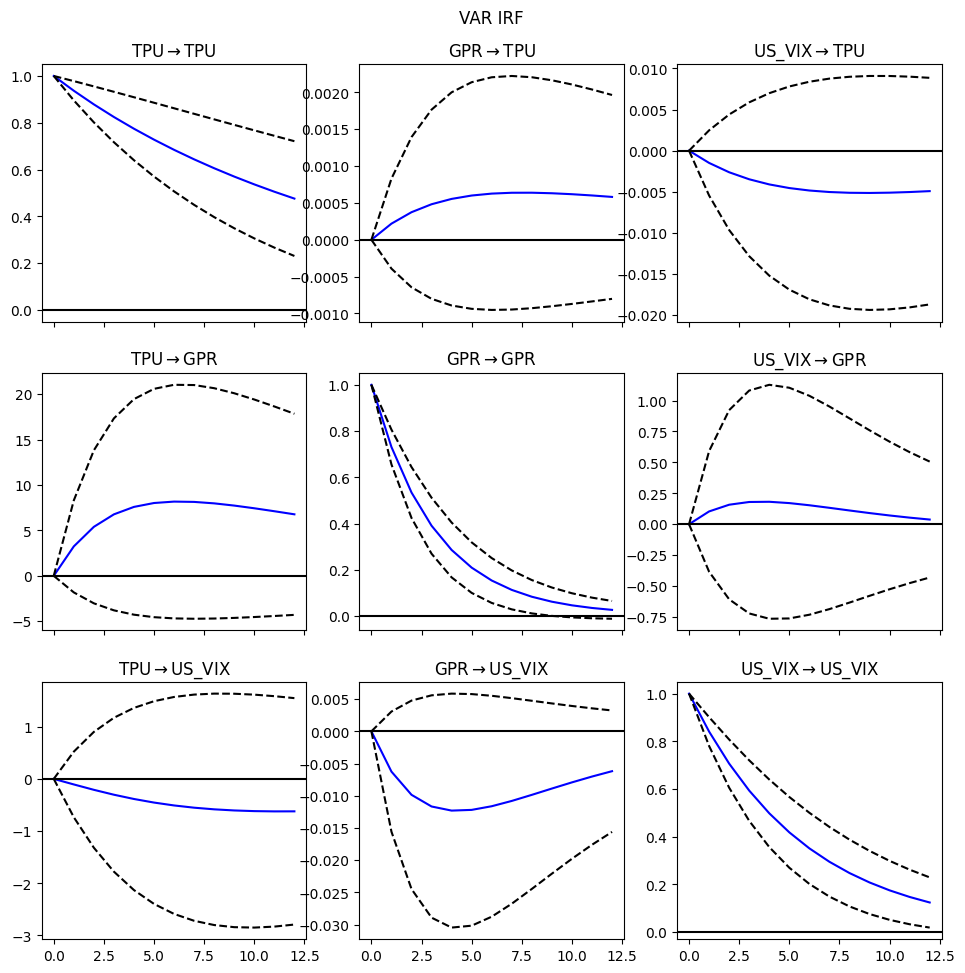


A matrix:
 [[ 1.  0.  0.]
 [nan  1.  0.]
 [nan nan  1.]]

❌ SVAR FAILED: zero-size array to reduction operation maximum which has no identity

👉 Likely reasons:
- Too many variables
- Multicollinearity
- Insufficient data
- Weak identification

✅ CODE COMPLETED SUCCESSFULLY


In [ ]:
# =====================================================
# 0) IMPORT LIBRARIES
# =====================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.svar_model import SVAR

# =====================================================
# 1) LOAD STATIONARY DATA
# =====================================================
df = pd.read_excel("final_transformed_dataset.xlsx", sheet_name="Transformed_Data")

# =====================================================
# 2) SELECT VARIABLES (REDUCED FOR STABILITY)
# =====================================================
# 🔥 IMPORTANT: Keep ONLY 3–4 variables for SVAR stability
cols = ["TPU", "GPR", "US_VIX"]

print("\nSelected columns:", cols)

# =====================================================
# 3) CLEAN DATA
# =====================================================
data = df[cols].copy()

print("\nShape BEFORE dropna:", data.shape)
print("\nMissing values:\n", data.isna().sum())

data = data.dropna().reset_index(drop=True)

print("\nShape AFTER dropna:", data.shape)

# Check variability
print("\nStandard deviation:\n", data.std())

# Safety check
if data.shape[0] < 60:
    raise ValueError("❌ Too few observations. Need at least ~60 for SVAR.")

# =====================================================
# 4) FIT VAR MODEL
# =====================================================
model = VAR(data)

lag_selection = model.select_order(maxlags=4)
print("\nLag Selection:\n", lag_selection.summary())

# 🔥 FORCE small lag (important for SVAR stability)
p = 1
print("\nUsing lag:", p)

var_res = model.fit(p)

print("\n===== VAR RESULTS =====\n")
print(var_res.summary())

# =====================================================
# 5) VAR IMPULSE RESPONSE
# =====================================================
irf_var = var_res.irf(12)
irf_var.plot()
plt.suptitle("VAR IRF")
plt.show()

# =====================================================
# 6) SVAR MODEL (ROBUST VERSION)
# =====================================================
k = data.shape[1]

# Lower triangular A matrix
A = np.full((k, k), np.nan)
np.fill_diagonal(A, 1)

for i in range(k):
    for j in range(i+1, k):
        A[i, j] = 0

print("\nA matrix:\n", A)

# =====================================================
# 7) SAFE SVAR EXECUTION
# =====================================================
try:
    # 🔥 Use lag = 1 ALWAYS for stability
    svar_model = SVAR(data, svar_type='A', A=A)
    svar_res = svar_model.fit(maxlags=1)

    print("\n✅ SVAR ESTIMATION SUCCESSFUL")

    print("\nSVAR Parameters:\n", svar_res.params)
    print("\nEstimated A matrix:\n", svar_res.A)

    # =====================================================
    # 8) SVAR IMPULSE RESPONSE
    # =====================================================
    irf_svar = svar_res.irf(12)
    irf_svar.plot()
    plt.suptitle("SVAR IRF")
    plt.show()

except Exception as e:
    print("\n❌ SVAR FAILED:", e)

    print("\n👉 Likely reasons:")
    print("- Too many variables")
    print("- Multicollinearity")
    print("- Insufficient data")
    print("- Weak identification")

# =====================================================
# 9) FINAL MESSAGE
# =====================================================
print("\n✅ CODE COMPLETED SUCCESSFULLY")